In [ ]:
import os
import re
import sys
import glob
import math
import subprocess
import urllib.request
from collections import Counter

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

In [ ]:
DRIVE_FILE_ID = "1hwmBuaZnr2T3ijfN5_UcZZeoWlwKjEQ9"
LOCAL_FILENAME = "cases_train2.xlsx"
INPUT_FILE = None
CASE_COLUMN = "Кейс"
TEXT_COLUMN = "Решение кейса"
ALL_SHEETS = True
TOP_N = 15
MIN_WORD_LEN = 3
LEMMATIZE = True
REMOVE_DOMAIN_WORDS = True
REMOVE_TEMPLATE_WORDS = True
EXTRA_STOPWORDS = {"ок", "ща", "крч", "это", "очень", "просто", "ну"}
OUTPUT_DIR = "top_words_output"

In [ ]:
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    matplotlib.use("Agg")


def _pip_install(*packages):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *packages],
                   check=False, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)


try:
    from wordcloud import WordCloud
except ImportError:
    _pip_install("wordcloud")
    try:
        from wordcloud import WordCloud
    except ImportError:
        WordCloud = None
        print("wordcloud не установлен — облака слов будут пропущены, графики-столбцы построятся.")

In [ ]:
morph = None
if LEMMATIZE:
    try:
        import pymorphy3
    except ImportError:
        _pip_install("pymorphy3")
        try:
            import pymorphy3
        except ImportError:
            pymorphy3 = None
    if pymorphy3 is not None:
        morph = pymorphy3.MorphAnalyzer()
    else:
        print("pymorphy3 не установлен — формы слов склеиваются упрощённо (отбрасывается окончание), "
              "возможны небольшие неточности.")

BASE_STOPWORDS = set("""
а без более больше будет будто бы был была были было быть в вам вас вдруг ведь во вот впрочем все всего всех всю вы г где да даже два
для до другой его ее ей ему если есть еще ж же за зачем здесь и из или им иногда их к как какая какой когда конечно кто куда ли лучше
между меня мне много может можно мой моя мы на над надо наконец нас не него нее ней нельзя нет ни нибудь никогда ним них ничего но ну о об
один он она они опять от перед по под после потом потому почти при про раз разве с сам свою себе себя сейчас со совсем так такой там тебя тем
теперь то тогда того тоже только том тот три тут ты у уж уже хорошо хоть чего чем через что чтоб чтобы чуть эти этого этой этом этот эту я
который которые которая которого которой которых также либо свой наш ваш весь вся всё еще ещё нём
""".split())

In [ ]:
DOMAIN_STOPWORDS = set("""
альфа банк банка банку банков банки клиент клиента клиентов клиенты рубль рублей рубля руб млн млрд тыс мес
миллион миллионов миллиона тысяча тысяч миллиард миллиардов год года году лет сегмент сегмента сегменты решение решения предлагать предлагаю выбрать выбрал отрасль
являться также например около примерно
""".split())
TEMPLATE_STOPWORDS = set("""
целевая целевой аудитория аудитории проблема проблемы проблем решение финансовая финансовый модель метрики
риски риск доказательства доказательство интервью опрос опросы партнеры партнер разработка доход доходы выручка
окупаемость окупится итого чел данные средний нужны нужно хотят
барьер барьеры кейс кейса кейсе продукт вероятность высокая средняя низкая отраслевое отраслевой
собственное собственный исследование открытые открытый
""".split())

In [ ]:
def get_stopwords():
    stop = set(BASE_STOPWORDS) | {w.lower() for w in EXTRA_STOPWORDS}
    if REMOVE_DOMAIN_WORDS:
        stop |= DOMAIN_STOPWORDS
    if REMOVE_TEMPLATE_WORDS:
        stop |= TEMPLATE_STOPWORDS
    try:
        import nltk
        from nltk.corpus import stopwords
        try:
            stop |= set(stopwords.words("russian"))
        except LookupError:
            nltk.download("stopwords", quiet=True)
            stop |= set(stopwords.words("russian"))
    except Exception:
        pass
    return stop


STOPWORDS = get_stopwords()
_lemma_cache = {}


_ENDINGS = sorted("""ами ями ого его ому ему ыми ими ов ев ей ой ий ый ая яя ое ее ые ие ых их ом ем ам ям ах ях
ою ею ую юю а я ы и у ю е о ь й""".split(), key=len, reverse=True)
_surface = {}

In [ ]:
def light_stem(word):
    """Запасной вариант без pymorphy3: грубо отрезаем окончание, чтобы склеить формы слова."""
    for end in _ENDINGS:
        if word.endswith(end) and len(word) - len(end) >= 4:
            return word[:-len(end)]
    return word


def normalize(word):
    word = word.replace("ё", "е")
    if morph is None:
        return light_stem(word) if LEMMATIZE else word
    if word not in _lemma_cache:
        _lemma_cache[word] = morph.parse(word)[0].normal_form.replace("ё", "е")
    return _lemma_cache[word]

In [ ]:
def display_form(token):
    """Для запасного режима: самая частая реальная форма слова вместо обрезанной основы."""
    if morph is not None or token not in _surface:
        return token
    return _surface[token].most_common(1)[0][0]

STOPWORDS |= {normalize(w) for w in list(STOPWORDS)}


def clean_text(text):
    text = re.sub(r"<[^>]+>", " ", str(text))
    text = re.sub(r"https?://\S+", " ", text)
    text = re.sub(r"\[\d+\]", " ", text)
    return text

In [ ]:
def tokenize(text):
    words = re.findall(r"[a-zа-яё]+", clean_text(text).lower())
    result = []
    for w in words:
        if len(w) < MIN_WORD_LEN:
            continue
        lemma = normalize(w)
        if lemma in STOPWORDS or w.replace("ё", "е") in STOPWORDS or len(lemma) < MIN_WORD_LEN:
            continue
        if morph is None and LEMMATIZE:
            _surface.setdefault(lemma, Counter())[w.replace("ё", "е")] += 1
        result.append(lemma)
    return result


def download_from_drive(file_id, dest):
    """Пробует скачать файл с Google Drive (нужен доступ 'по ссылке')."""
    urls = [
        f"https://docs.google.com/spreadsheets/d/{file_id}/export?format=xlsx",
        f"https://drive.google.com/uc?export=download&id={file_id}",
    ]
    for url in urls:
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            data = urllib.request.urlopen(req, timeout=60).read()
            if data[:2] == b"PK":
                with open(dest, "wb") as f:
                    f.write(data)
                print(f"Файл скачан с Google Drive -> {dest}")
                return dest
        except Exception:
            continue
    return None

In [ ]:
def locate_input_file():
    if INPUT_FILE:
        if not os.path.isfile(INPUT_FILE):
            raise FileNotFoundError(f"Файл не найден: {INPUT_FILE}")
        return INPUT_FILE
    for candidate in (LOCAL_FILENAME, os.path.join("/content", LOCAL_FILENAME)):
        if os.path.isfile(candidate):
            return candidate
    path = download_from_drive(DRIVE_FILE_ID, LOCAL_FILENAME)
    if path:
        return path
    if IN_COLAB:
        from google.colab import files
        print("Не удалось скачать файл автоматически (проверьте, что доступ по ссылке открыт).")
        print("Загрузите cases_train2.xlsx вручную:")
        uploaded = files.upload()
        if not uploaded:
            raise RuntimeError("Файл не загружен.")
        return list(uploaded.keys())[0]
    found = glob.glob("*.xlsx")
    if len(found) == 1:
        return found[0]
    raise FileNotFoundError(
        "Не удалось получить файл. Положите cases_train2.xlsx рядом со скриптом "
        "или задайте INPUT_FILE. Найдено xlsx: " + (", ".join(found) or "нет")
    )

In [ ]:
def read_table(path):
    if path.lower().endswith(".csv"):
        try:
            return pd.read_csv(path)
        except UnicodeDecodeError:
            return pd.read_csv(path, encoding="cp1251")
    if not ALL_SHEETS:
        return pd.read_excel(path)
    sheets = pd.read_excel(path, sheet_name=None)
    frames = []
    print(f"Листов в файле: {len(sheets)}")
    for name, sheet in sheets.items():
        if TEXT_COLUMN not in sheet.columns:
            print(f"  лист '{name}': нет столбца '{TEXT_COLUMN}' — пропускаю (столбцы: {list(sheet.columns)})")
            continue
        if CASE_COLUMN not in sheet.columns:
            sheet = sheet.copy()
            sheet[CASE_COLUMN] = name
            print(f"  лист '{name}': нет столбца '{CASE_COLUMN}', использую имя листа как кейс")
        print(f"  лист '{name}': строк {len(sheet)}")
        frames.append(sheet)
    if not frames:
        raise KeyError(f"Ни на одном листе нет столбца '{TEXT_COLUMN}'.")
    return pd.concat(frames, ignore_index=True)

In [ ]:
def check_columns(df):
    missing = [c for c in (CASE_COLUMN, TEXT_COLUMN) if c not in df.columns]
    if missing:
        raise KeyError(f"В файле нет столбцов {missing}. Есть: {list(df.columns)}. "
                       f"Поправьте CASE_COLUMN / TEXT_COLUMN в настройках.")


def case_label(value):
    try:
        return f"Кейс {int(float(value))}"
    except (TypeError, ValueError):
        return str(value)


def natural_key(label):
    """'Кейс 2' < 'Кейс 10': сортировка по числам внутри строки."""
    return [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", str(label))]


def build_counters(df):
    """df[CASE_COLUMN] к этому моменту уже содержит подписи вида 'Кейс N'."""
    counters = {}
    work = df.dropna(subset=[CASE_COLUMN, TEXT_COLUMN])
    for label in sorted(work[CASE_COLUMN].unique(), key=natural_key):
        words = []
        for text in work.loc[work[CASE_COLUMN] == label, TEXT_COLUMN]:
            words.extend(tokenize(text))
        merged = Counter()
        for token, count in Counter(words).items():
            merged[display_form(token)] += count
        counters[label] = merged
    return counters

In [ ]:
def distinctive_words(counters, top_n, min_count=2):
    """TF-IDF, где 'документ' = все тексты одного кейса."""
    import math
    n_cases = len(counters)
    df_count = Counter()
    for cnt in counters.values():
        df_count.update(cnt.keys())
    result = {}
    for case, cnt in counters.items():
        total = sum(cnt.values()) or 1
        scores = {
            w: (c / total) * (math.log((1 + n_cases) / (1 + df_count[w])) + 1)
            for w, c in cnt.items() if c >= min_count
        }
        top = sorted(scores, key=scores.get, reverse=True)[:top_n]
        result[case] = [(w, cnt[w]) for w in top]
    return result

In [ ]:
def _grid(n, max_cols):
    cols = min(max_cols, max(n, 1))
    return cols, (n + cols - 1) // cols


def plot_bars(top_by_case, title_suffix, color, path):
    cases = list(top_by_case.keys())
    cols, rows = _grid(len(cases), 2)
    fig, axes = plt.subplots(rows, cols, figsize=(7 * cols, 3.8 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, case in zip(axes.flat, cases):
        ax.axis("on")
        top = top_by_case[case][::-1]
        if top:
            ax.barh([w for w, _ in top], [c for _, c in top], color=color)
        ax.set_title(f"{case}: {title_suffix}")
        ax.set_xlabel("Частота")
    plt.tight_layout()
    plt.savefig(path, dpi=130)
    if IN_COLAB:
        plt.show()
    plt.close()

In [ ]:
def plot_clouds(counters, path):
    if WordCloud is None:
        return False
    cases = list(counters.keys())
    cols, rows = _grid(len(cases), 3)
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 5 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, case in zip(axes.flat, cases):
        if not counters[case]:
            continue
        wc = WordCloud(width=900, height=700, background_color="white", colormap="viridis",
                       collocations=False, random_state=1).generate_from_frequencies(dict(counters[case]))
        ax.imshow(wc, interpolation="bilinear")
        ax.set_title(case)
    plt.tight_layout()
    plt.savefig(path, dpi=130)
    if IN_COLAB:
        plt.show()
    plt.close()
    return True

Листов в файле: 1
  лист 'Лист1': строк 2388
Строк всего: 2388, кейсов: 10
Строк по кейсам:
Кейс
Кейс 1     454
Кейс 2     215
Кейс 3     213
Кейс 4     215
Кейс 5     215
Кейс 6     215
Кейс 7     207
Кейс 8     224
Кейс 9     215
Кейс 10    215

=== Кейс 1 — самые частые слова ===
 1. кредит                 325
 2. интеграция             303
 3. закупка                268
 4. рынок                  236
 5. бизнес                 224
 6. поставщик              203
 7. день                   200
 8. малый                  195
 9. сервис                 189
10. система                183
11. первый                 179
12. рост                   178
13. факторинг              173
14. оборудование           171
15. анализ                 164

=== Кейс 2 — самые частые слова ===
 1. кредит                 206
 2. центр                  179
 3. район                  175
 4. город                  174
 5. ребенок                150
 6. месяц                  148
 7. сделать                1

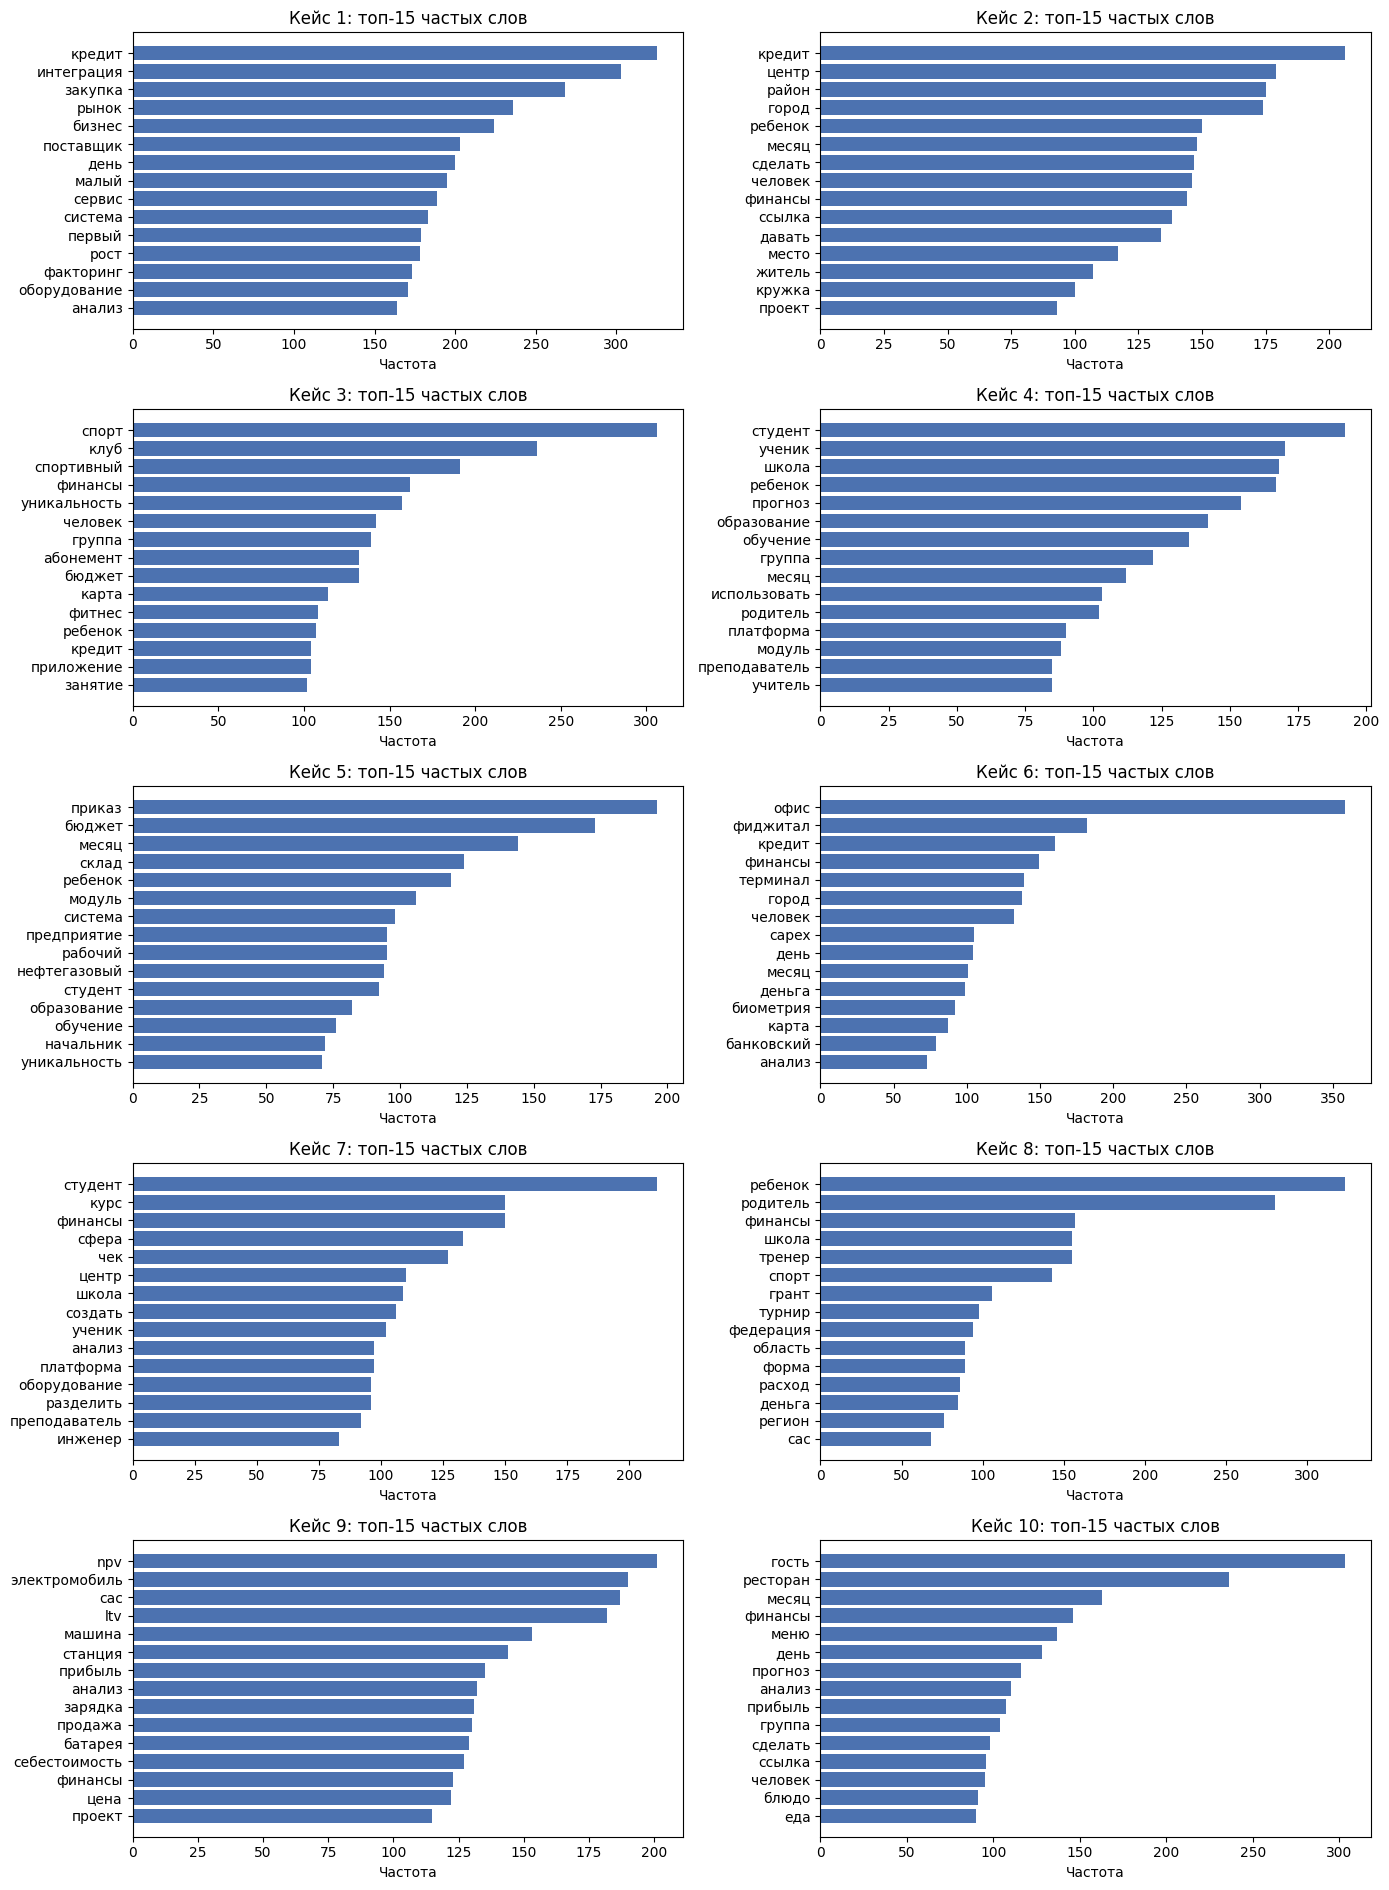

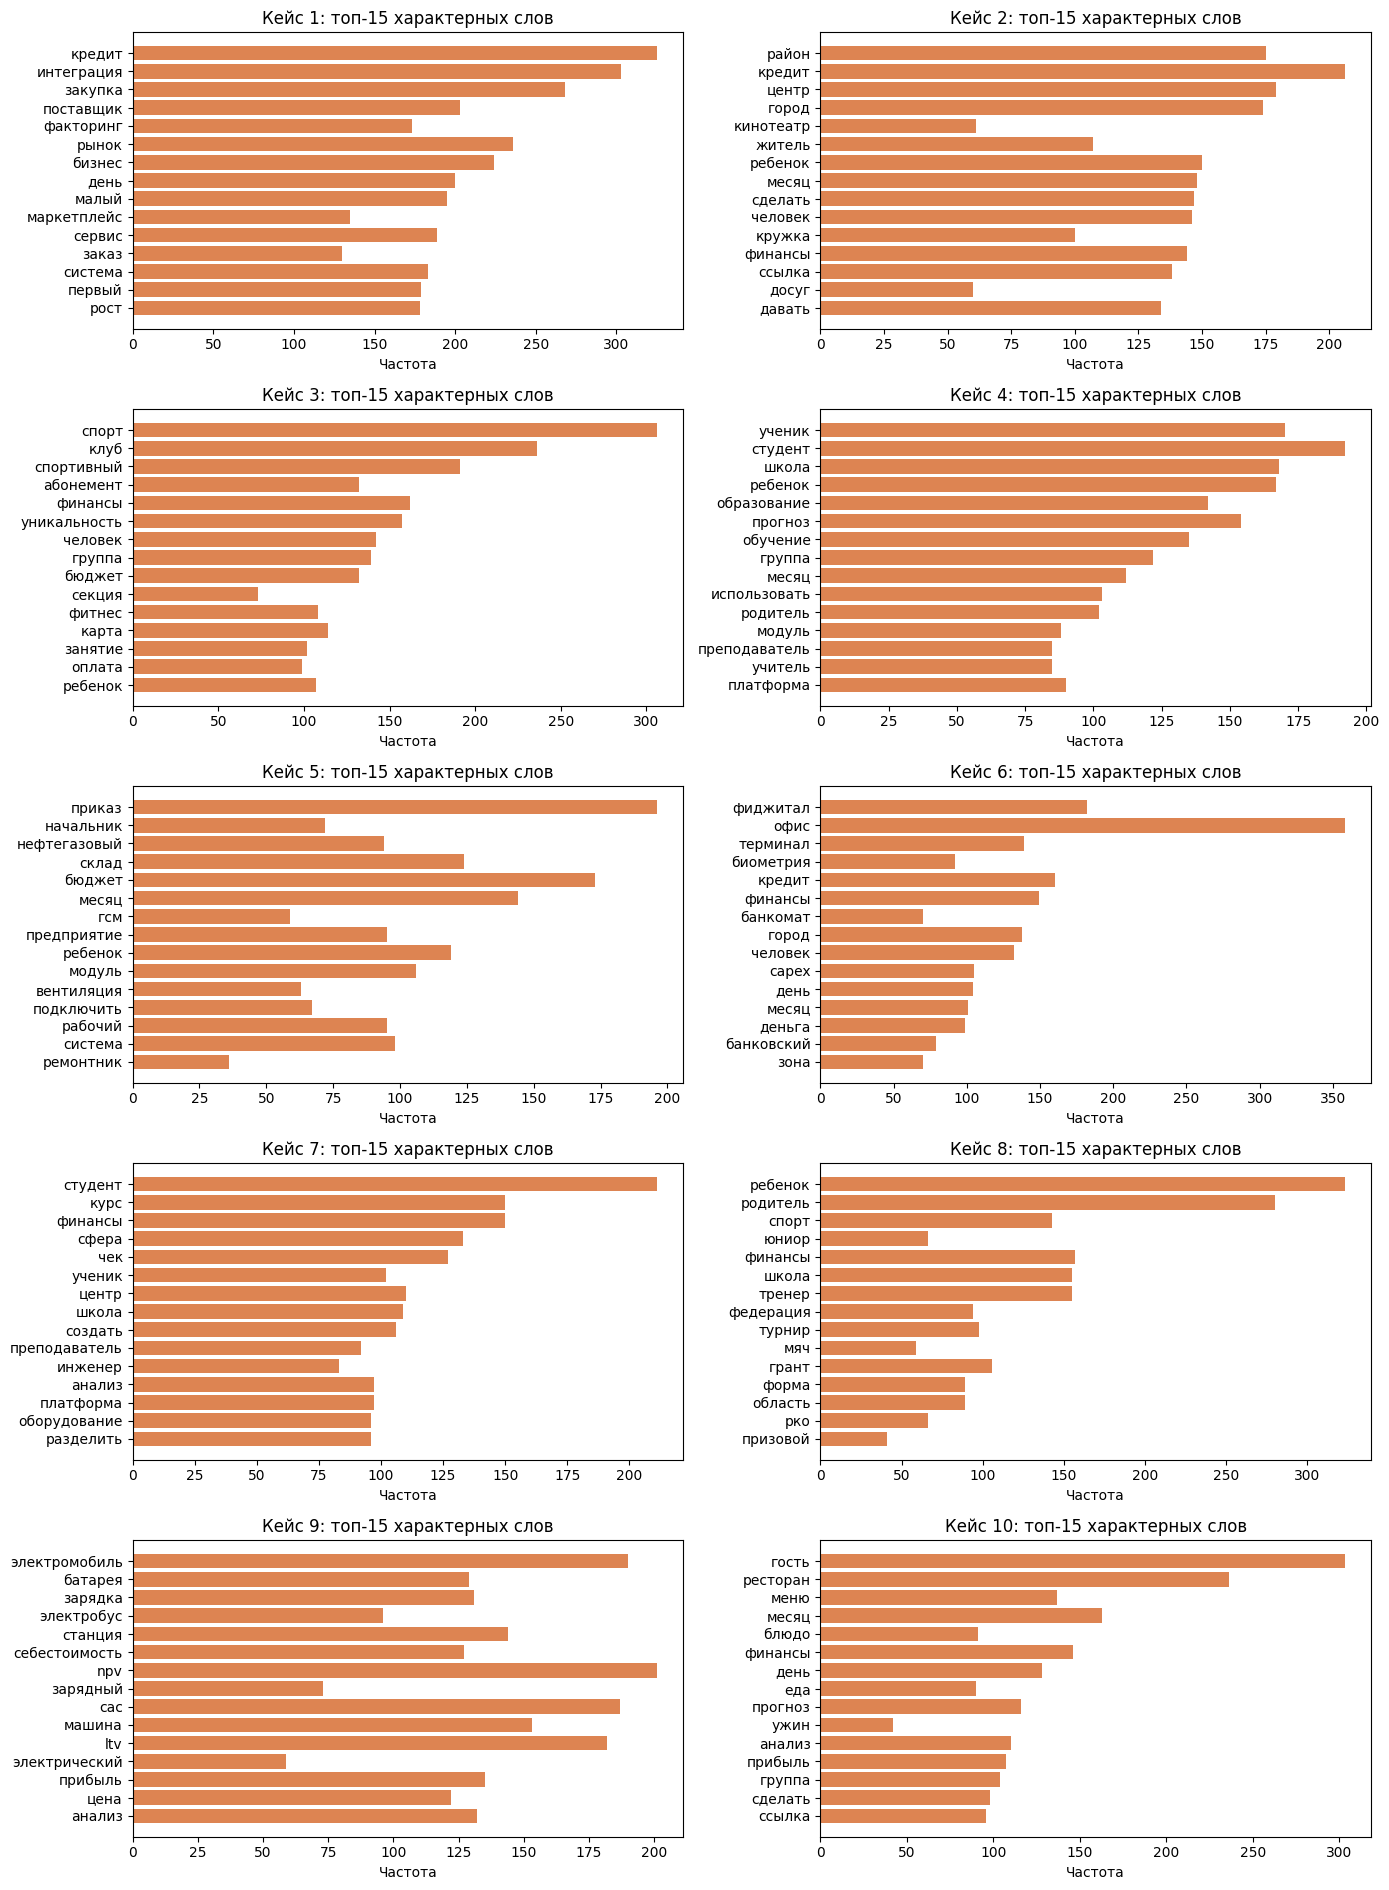

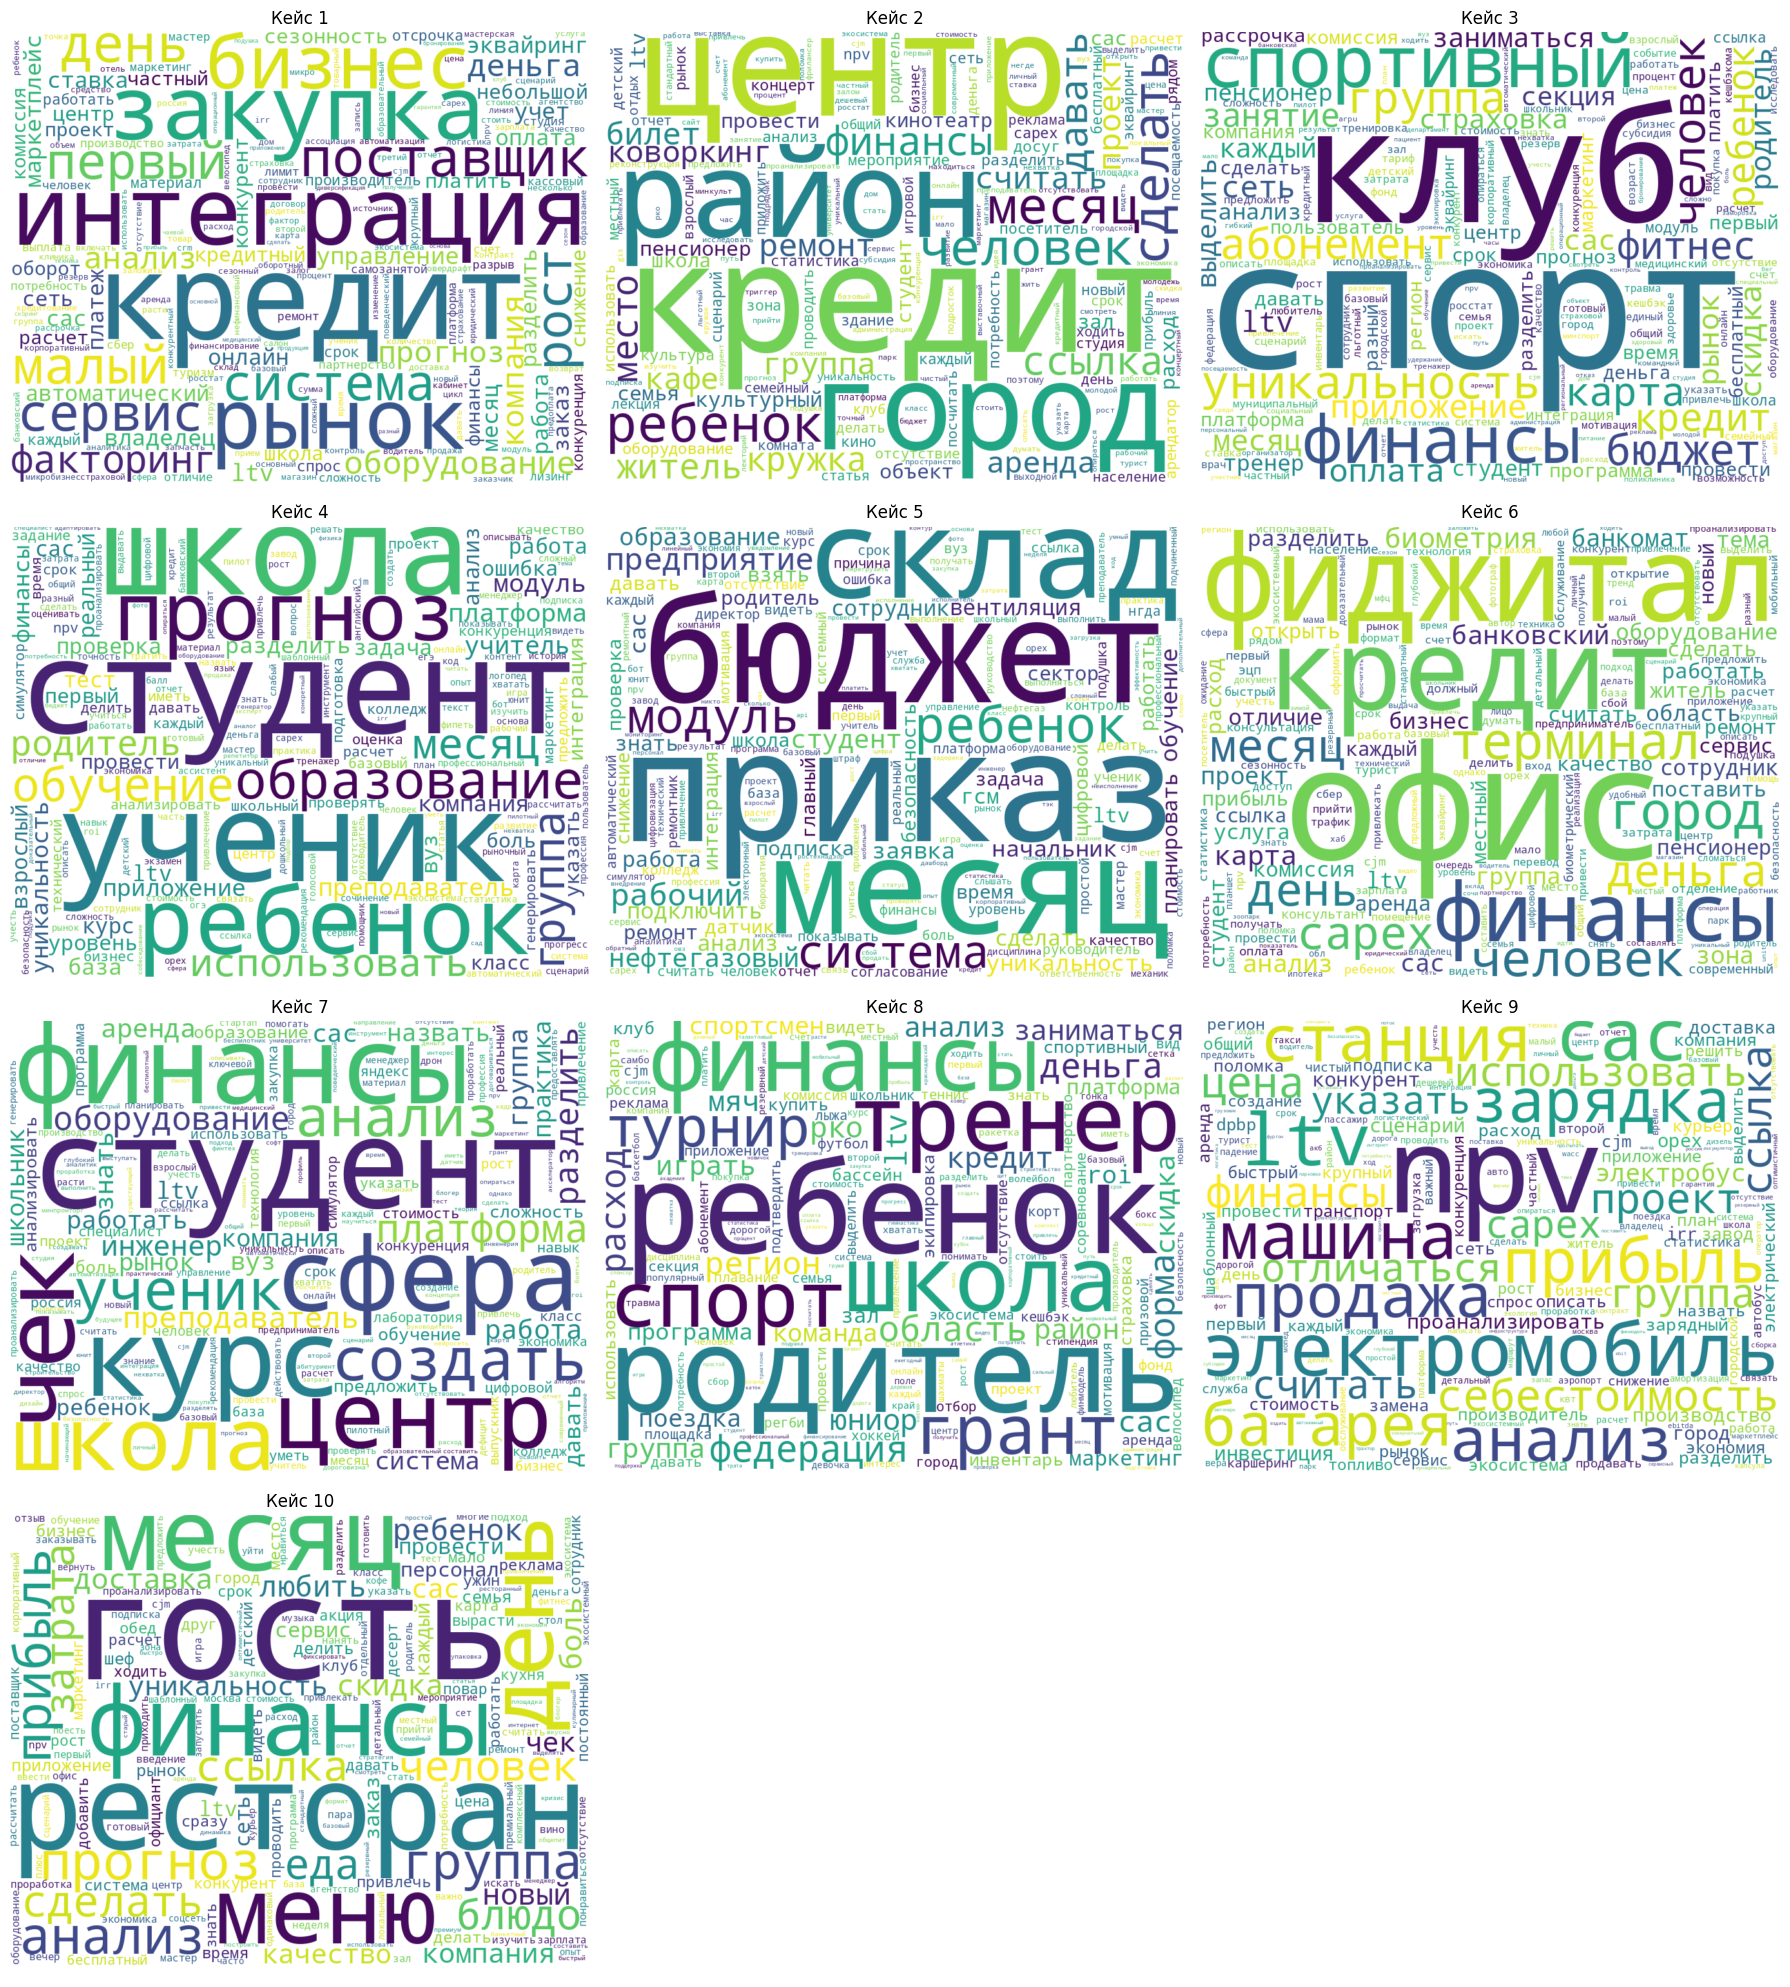

In [ ]:
def print_block(title, by_case):
    for case, items in by_case.items():
        print(f"\n=== {case} — {title} ===")
        for rank, (word, count) in enumerate(items, 1):
            print(f"{rank:>2}. {word:<22} {count}")


def main():
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    df = read_table(locate_input_file())
    check_columns(df)
    df[CASE_COLUMN] = df[CASE_COLUMN].map(lambda v: case_label(v) if pd.notna(v) else v)
    print(f"Строк всего: {len(df)}, кейсов: {df[CASE_COLUMN].nunique()}")
    empty = df[CASE_COLUMN].isna().sum() + df[TEXT_COLUMN].isna().sum()
    if empty:
        print(f"Внимание: пустых значений в '{CASE_COLUMN}' / '{TEXT_COLUMN}': {empty} (такие строки пропускаются)")
    print("Строк по кейсам:")
    counts = df[CASE_COLUMN].value_counts()
    print(counts.reindex(sorted(counts.index, key=natural_key)).to_string())

    counters = build_counters(df)
    top_freq = {case: cnt.most_common(TOP_N) for case, cnt in counters.items()}
    top_dist = distinctive_words(counters, TOP_N)

    print_block("самые частые слова", top_freq)
    print_block("характерные слова (TF-IDF)", top_dist)

    plot_bars(top_freq, f"топ-{TOP_N} частых слов", "#4C72B0", os.path.join(OUTPUT_DIR, "top_words_bars.png"))
    plot_bars(top_dist, f"топ-{TOP_N} характерных слов", "#DD8452", os.path.join(OUTPUT_DIR, "distinctive_words_bars.png"))
    made_clouds = plot_clouds(counters, os.path.join(OUTPUT_DIR, "wordclouds.png"))


if __name__ == "__main__":
    main()